# Topic 23 - Capstone Project

## Every skill so far, on data nobody handed you

Fourteen topics back, this course started with variables and control flow. Since then, every lesson has worked from a dataset built for you - synthetic, Ghana-contextualised, with just enough realistic mess to teach the point of that lesson and no more. That was deliberate: you needed to learn wrangling without also fighting an unfamiliar dataset, learn visualization without also deciding what was worth charting, learn EDA without also wondering whether the data could be trusted at all.

The capstone removes that scaffolding. **Nobody gives you a dataset for this one.** You find it, you decide whether it is good enough to use, you decide what questions it can actually answer, and you carry it through the whole pipeline - gather, wrangle, explore, visualize, write up - on your own judgement. That is the actual job of a data analyst: not executing a pipeline someone else designed, but deciding whether this data, right here, supports the claim you are about to make.

Two new, small tools join the kit first - SQL and simple regression - because the README promised them and because real data often arrives in a database, and some real questions are "how much does Y change when X changes," which the tools you already have do not answer directly.

## Learning objectives

By the end of this lesson you should be able to:

- query a dataset with basic SQL (`SELECT`, `WHERE`, `GROUP BY`, `JOIN`) and recognise its pandas equivalent;
- fit and interpret a simple linear regression, including when R² says the fit is not worth trusting;
- evaluate a candidate dataset against a real checklist before committing to it;
- turn a dataset into a written plan - specific questions, expected deliverables, stated risks - before writing any analysis code;
- carry one dataset through the full pipeline from Topics 19-22: gather, wrangle, explore, visualize, and write both report types;
- judge your own finished project against a rubric that does not know your dataset in advance.

## The capstone contract

| Stage | What you already know | From |
|---|---|---|
| Gather | Find real data, check it before trusting it | Topic 19 |
| Wrangle | Combine, clean, validate every join | Topic 20 |
| Explore | Ask good questions, univariate -> bivariate -> multivariate, pattern vs. noise | Topic 22 |
| Visualize | The right chart for the question, titled with the finding | Topic 21 |
| Model *(optional)* | A simple regression, judged by R², not just fitted | 23b |
| Write up | A wrangling report and an act report, for two different readers | Topic 22 |

Nothing in that table is new except the "model" row. The capstone is not a ninth skill - it is proof that the first eight compose into one project without you needing to be told the order.

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "capstone_project" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/capstone_project/data
files:             ['air_quality_readings.csv', 'air_quality_stations.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# The retail "2023 Trading Review" table from Topic 20, reused throughout
# this topic exactly as Topic 22 reused it for the two report types.
def clean_region(series):
    return (series.str.strip().str.replace(r"\s+", " ", regex=True).str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    expected_rows = len(orders)
    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")
    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))
    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)
    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)
    if len(table) != expected_rows:
        raise ValueError("Row count changed during wrangling.")
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Retail analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")

Retail analysis table: 1200 rows x 23 columns


---

## What's new: SQL

Pandas and SQL answer the same questions about tabular data; SQL is simply the language most real databases speak, so knowing both means you are never blocked by *where* the data happens to live.

In [3]:
import sqlite3

conn = sqlite3.connect(":memory:")
orders.to_sql("orders", conn, index=False)

pandas_answer = len(orders[orders["channel"] == "Shop"])
sql_answer = pd.read_sql_query("SELECT COUNT(*) AS n FROM orders WHERE channel = 'Shop'", conn)["n"].iloc[0]
print(f"pandas: {pandas_answer} orders through the Shop channel")
print(f"SQL:    {sql_answer} orders through the Shop channel")
print("Same answer, two languages:", pandas_answer == sql_answer)

pandas: 543 orders through the Shop channel
SQL:    543 orders through the Shop channel
Same answer, two languages: True


Section 23a covers `GROUP BY` and `JOIN` the same way - side by side with the pandas you already know, not as a replacement for it.

---

## What's new: simple regression

A correlation coefficient says two things move together. A **regression line** goes further: it claims a specific equation - for every one-unit increase in X, Y changes by *this much* - which is a stronger claim and needs more scrutiny before you trust it.

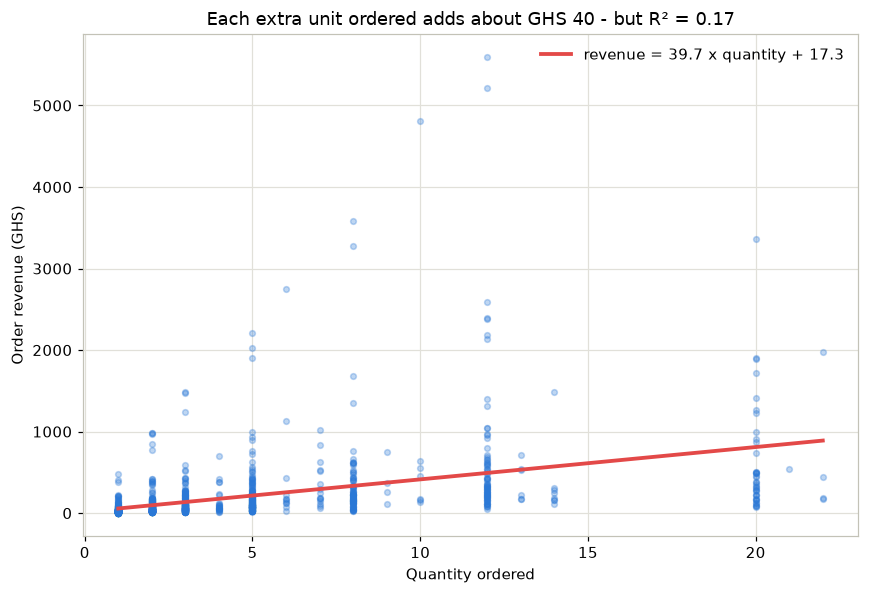

R-squared: 0.172 - quantity alone explains about 17% of the variation in revenue.
The rest comes from unit price, which this line does not know about at all.


In [4]:
x = analysis["quantity"].values.astype(float)
y = analysis["revenue_ghs"].values

slope, intercept = np.polyfit(x, y, 1)
predicted = slope * x + intercept
ss_res = ((y - predicted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(x, y, s=14, alpha=0.3, color=PALETTE["blue"])
x_line = np.linspace(x.min(), x.max(), 50)
ax.plot(x_line, slope * x_line + intercept, color=PALETTE["red"], linewidth=2.5,
        label=f"revenue = {slope:.1f} x quantity + {intercept:.1f}")
ax.set_title(f"Each extra unit ordered adds about GHS {slope:.0f} - but R² = {r_squared:.2f}")
ax.set_xlabel("Quantity ordered")
ax.set_ylabel("Order revenue (GHS)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"R-squared: {r_squared:.3f} - quantity alone explains about {r_squared * 100:.0f}% of the variation in revenue.")
print("The rest comes from unit price, which this line does not know about at all.")

R² = 0.172 is a real, usable relationship - not a strong one. The line is not wrong, but a claim like "order size predicts revenue" overstates what 17% of explained variance actually supports. Section 23b covers reading R² and residuals properly, including a second example where the fit is even weaker.

---

## Finding your own data

Topic 19 already built the resource you need for this: [Appendix A - Common Data Sources for Student Projects](../data_analysis_process/topic19b_appendix_common_data_sources.ipynb), with a source table (Kaggle, Our World in Data, World Bank DataBank, data.gov, Ghana Statistical Service, Google Dataset Search, GitHub) and ten evaluation questions to ask before committing to a dataset. Use it - do not go looking for a second list when a good one already exists.

A few more sources worth adding for a capstone's broader scope:

| Source | Good for |
|---|---|
| [UN Data](https://data.un.org/) | International development and demographic indicators |
| [WHO Global Health Observatory](https://www.who.int/data/gho) | Global health statistics by country |
| [FAOSTAT](https://www.fao.org/faostat/en/) | Global food and agriculture statistics |
| [Bank of Ghana](https://www.bog.gov.gh/) | Ghanaian monetary and financial statistics |
| [Ghana Open Data Initiative](https://data.gov.gh/) | Ghanaian government open datasets |

Section 23c practices Topic 19b's checklist directly, on three candidate datasets you did not pick yourself, before you apply it for real.

---

## From dataset to plan

Having a dataset is not having a project. Section 23d practices turning "I have this CSV" into a short written plan - three to five specific questions (22a's rule: specific, comparative, answerable), the deliverables you expect to produce, and the limitations you already know about before you have written a line of analysis code. Writing the risks down *first* is the whole point - a limitation you noticed in week one and a limitation you discover while writing the final report read very differently to someone grading the result.

## Key takeaways

- **The capstone adds no new analysis skill except regression** - gathering, wrangling, exploring, visualizing, and writing up are all Topics 19-22, applied without a provided dataset telling you what to do next.
- **SQL and pandas answer the same questions** - learn the mapping, not a second way of thinking about data.
- **A regression line is a stronger claim than a correlation coefficient**, and R² tells you how much of that claim to actually believe.
- **Topic 19b's data-source checklist already exists** - use it rather than rebuilding it, and apply it before you fall in love with a dataset, not after.
- **A written plan - questions, deliverables, risks - belongs before the analysis**, not reconstructed afterward to match what you happened to find.
- **The project is graded by structure, not by a known answer key** - nobody else has your dataset, so the rubric checks what any good project has (reports of the right shape, enough charts, a question that was actually answered), not a specific number.

## Further reading and the course path

### On SQL and regression
- [SQLite: SQL as understood by SQLite](https://www.sqlite.org/lang.html)
- [pandas: Comparison with SQL](https://pandas.pydata.org/docs/getting_started/comparison/comparison_with_sql.html)
- [NumPy: `polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html)

### Practice notebooks for this topic
- [23a - SQL basics](topic23a_sql_basics.ipynb)
- [23b - Simple regression](topic23b_simple_regression.ipynb)
- [23c - Choosing your dataset](topic23c_choosing_your_dataset.ipynb)
- [23d - Planning your analysis](topic23d_planning_your_analysis.ipynb)

### The capstone
- [Topic 23 - the capstone project brief](assignments/topic23_capstone_project_brief.ipynb)
- [Topic 19b - Common data sources](../data_analysis_process/topic19b_appendix_common_data_sources.ipynb)
- [Topic 19d - Submitting your work with GitHub](../data_analysis_process/topic19d_appendix_submitting_with_github.ipynb)

### Elsewhere in the course
- [Topic 20 - Data wrangling](../data_wrangling/topic20_data_wrangling.ipynb)
- [Topic 21 - Data visualization](../data_visualization/topic21_data_visualization.ipynb)
- [Topic 22 - Exploratory data analysis](../exploratory_data_analysis/topic22_exploratory_data_analysis.ipynb)